# Examine De ordine mundi

This notebook evaluates the hold-out work "X_ordine" against the test corpus to assess whether it was likely authored by **H** (Hildebert).

## Approach

We use stylometric analysis (Lambda-G) to compare 100 random ~750-token samples from *De ordine* against known works by author H and M. A logistic regression model (trained in `evaluate_calibrate.ipynb`) converts raw scores into predicted probabilities.

## Stages

1. **Setup** — Load corpora and trained model
2. **Evaluation** — Run 100 parallel stylometric comparisons using Ray
3. **Visualization** — Histplot of raw scores + stripplot/violin of predicted probabilities

In [48]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import ray
from tqdm import tqdm
from typing import Any

from sentence_corpora import TwoLevelCorpus
from sentence_corpora.lambdag.av import LambdaGAV

import mpl_fontkit as fk

# Set up Roboto Condensed font
fk.install("Roboto Condensed")

# Set seaborn theme
sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={
        "figure.figsize": (10, 4),
        "figure.dpi": 300,
        "axes.facecolor": "white",
        "figure.facecolor": "white",
        "axes.unicode_minus": False,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
    },
)

Font name: `Roboto Condensed`


In [49]:
# Load corpora
test_corpus = TwoLevelCorpus.from_pickle("test_corpus.pkl")
ordine_corpus = TwoLevelCorpus.from_pickle("ordine_corpus.pkl")

print(
    f"ordine: {len(ordine_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in ordine_corpus)} tokens"
)
print(
    f"Test corpus: {len(test_corpus)} sentences, "
    f"{sum(len(s.text.split()) for s in test_corpus)} tokens"
)
print(f"Test corpus authors: {test_corpus.get_unique_values('author')}")

ordine: 281 sentences, 4084 tokens
Test corpus: 13997 sentences, 244334 tokens
Test corpus authors: ['AI', 'AeC', 'AeP', 'B', 'BC', 'DC', 'E', 'FB', 'GAp', 'GAr', 'GC', 'GM', 'GP', 'GVS', 'GiP', 'H', 'HA', 'HP', 'IH', 'II', 'M', 'NLC', 'OM', 'OSE', 'RC', 'RT', 'SG', 'U1', 'U10', 'U11', 'U2', 'U3', 'U4', 'U5', 'U6', 'U7', 'U8', 'U9']


In [50]:
# Sampling function
def sample_corpus_to_token_count(corpus, target_tokens: int, rng: Any):
    """Sample sentences from corpus until we reach approximately target_tokens.

    Shuffles sentences and adds them until we exceed target_tokens.
    """
    sentences = list(corpus)
    total_tokens = sum(len(s.text.split()) for s in sentences)

    if total_tokens <= target_tokens:
        raise ValueError(
            f"Corpus has only {total_tokens} tokens, which is less than target {target_tokens}"
        )

    shuffled = list(sentences)
    rng.shuffle(shuffled)

    sampled = []
    current_tokens = 0
    for s in shuffled:
        sampled.append(s)
        current_tokens += len(s.text.split())
        if current_tokens >= target_tokens:
            break

    return type(corpus)(sampled, levels=corpus.levels)

In [51]:
# Initialize Ray
ray.init(ignore_reinit_error=True)
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

2026-09-04 11:20:34,197	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


In [52]:
test_corpus.stats()

Author      Works    Sentences    Tokens    Mean Len
--------  -------  -----------  --------  ----------
AI              1          470     9,861        21
AeC             2          509    14,745        29
AeP             1          190     5,806        30.6
B               1          111     1,991        17.9
BC              1          830     6,994         8.4
DC              1          398     6,449        16.2
E               1          160     3,326        20.8
FB              1          775    10,684        13.8
GAp             1          423     6,004        14.2
GAr             1          532    11,367        21.4
GC              1          612    12,123        19.8
GM              1          184     3,379        18.4
GP              1          516    14,417        27.9
GVS             1          400     4,958        12.4
GiP             1          327     5,741        17.6
H               1          117     1,960        16.8
HA              1          372     5,049        13

### De ordine vs Hildebert

In [54]:
# Define the evaluation function for Ray
@ray.remote
def run_ordine_evaluation(
    seed: int,
    target_tokens: int = 750,
) -> dict:
    """Run a single AV evaluation: De ordine vs author H."""
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    # Sample ~750 tokens from De ordine as the unknown (q_corpus)
    q_corpus = sample_corpus_to_token_count(ordine_corpus, target_tokens, rng)

    result = av.run_single_av_problem(
        known_entity="H",
        q_corpus=q_corpus,
        kr_corpus=test_corpus,
        known_tokens=2000,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "score": result["score"],
        "corrected_score_sqrt": result["corrected_score_sqrt"],
        "corrected_score_hapax": result["corrected_score_hapax"],
        "n_unknown": result["unknown_sentences_used"],
        "unknown_tokens": result["unknown_tokens_used"],
    }

In [55]:
# Create 100 evaluation tasks
master_rng = np.random.default_rng(42)
TARGET_TOKENS = 750
N_EVALUATIONS = 100

print(f"Creating {N_EVALUATIONS} evaluation tasks...")
tasks = []
for i in range(N_EVALUATIONS):
    seed = master_rng.integers(0, 2**32 - 1)
    tasks.append(run_ordine_evaluation.remote(seed, TARGET_TOKENS))
print(f"✓ Created {len(tasks)} tasks")

Creating 100 evaluation tasks...
✓ Created 100 tasks


In [56]:
# Execute all tasks in parallel with progress bar
print("\nExecuting tasks in parallel...")
results = []

for _ in tqdm(range(len(tasks)), desc="Evaluations"):
    ready, _ = ray.wait(tasks, num_returns=1)
    result = ray.get(ready[0])
    results.append(result)
    tasks.remove(ready[0])

print(f"✓ Completed {len(results)} evaluations")
ray.shutdown()


Executing tasks in parallel...


Evaluations:   0%|                                     | 0/100 [00:00<?, ?it/s](pid=4255) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=4255)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=4255) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=4255)   from pandas.core import (
Evaluations: 100%|███████████████████████████| 100/100 [00:34<00:00,  2.91it/s]
(pid=4252) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster]
(pid=4252)   from pandas.core.computation.check import NUMEXPR_INSTALLED [repeated 7x across 

✓ Completed 100 evaluations


In [57]:
# Convert to DataFrame
df = pd.DataFrame(results)

print("=== Score Statistics ===")
print(df[["score", "corrected_score_sqrt", "corrected_score_hapax"]].describe())

print(f"\nUnknown token stats:")
print(f"  Mean: {df['unknown_tokens'].mean():.0f}")
print(f"  Min:  {df['unknown_tokens'].min()}")
print(f"  Max:  {df['unknown_tokens'].max()}")

=== Score Statistics ===
            score  corrected_score_sqrt  corrected_score_hapax
count  100.000000            100.000000             100.000000
mean     8.133268              0.294430               0.642561
std     37.624227              1.365358               2.967649
min    -87.207838             -3.165444              -6.319409
25%    -18.494138             -0.667172              -1.538079
50%      9.103208              0.330588               0.766924
75%     35.002327              1.265124               2.741682
max     77.451444              2.816882               6.044491

Unknown token stats:
  Mean: 759
  Min:  750
  Max:  806


In [58]:
# Load the trained logistic regression model and compute probabilities
model = joblib.load("logistic_regression_model_uncorrected.pkl")
df["probability"] = model.predict_proba(df["score"].values.reshape(-1, 1))[:, 1]

print("=== Probability Statistics ===")
print(df["probability"].describe())
print(f"\nMean probability: {df['probability'].mean():.4f}")
print(f"Median probability: {df['probability'].median():.4f}")

=== Probability Statistics ===
count    100.000000
mean       0.265420
std        0.253041
min        0.001486
25%        0.046139
50%        0.163664
75%        0.420799
max        0.861846
Name: probability, dtype: float64

Mean probability: 0.2654
Median probability: 0.1637


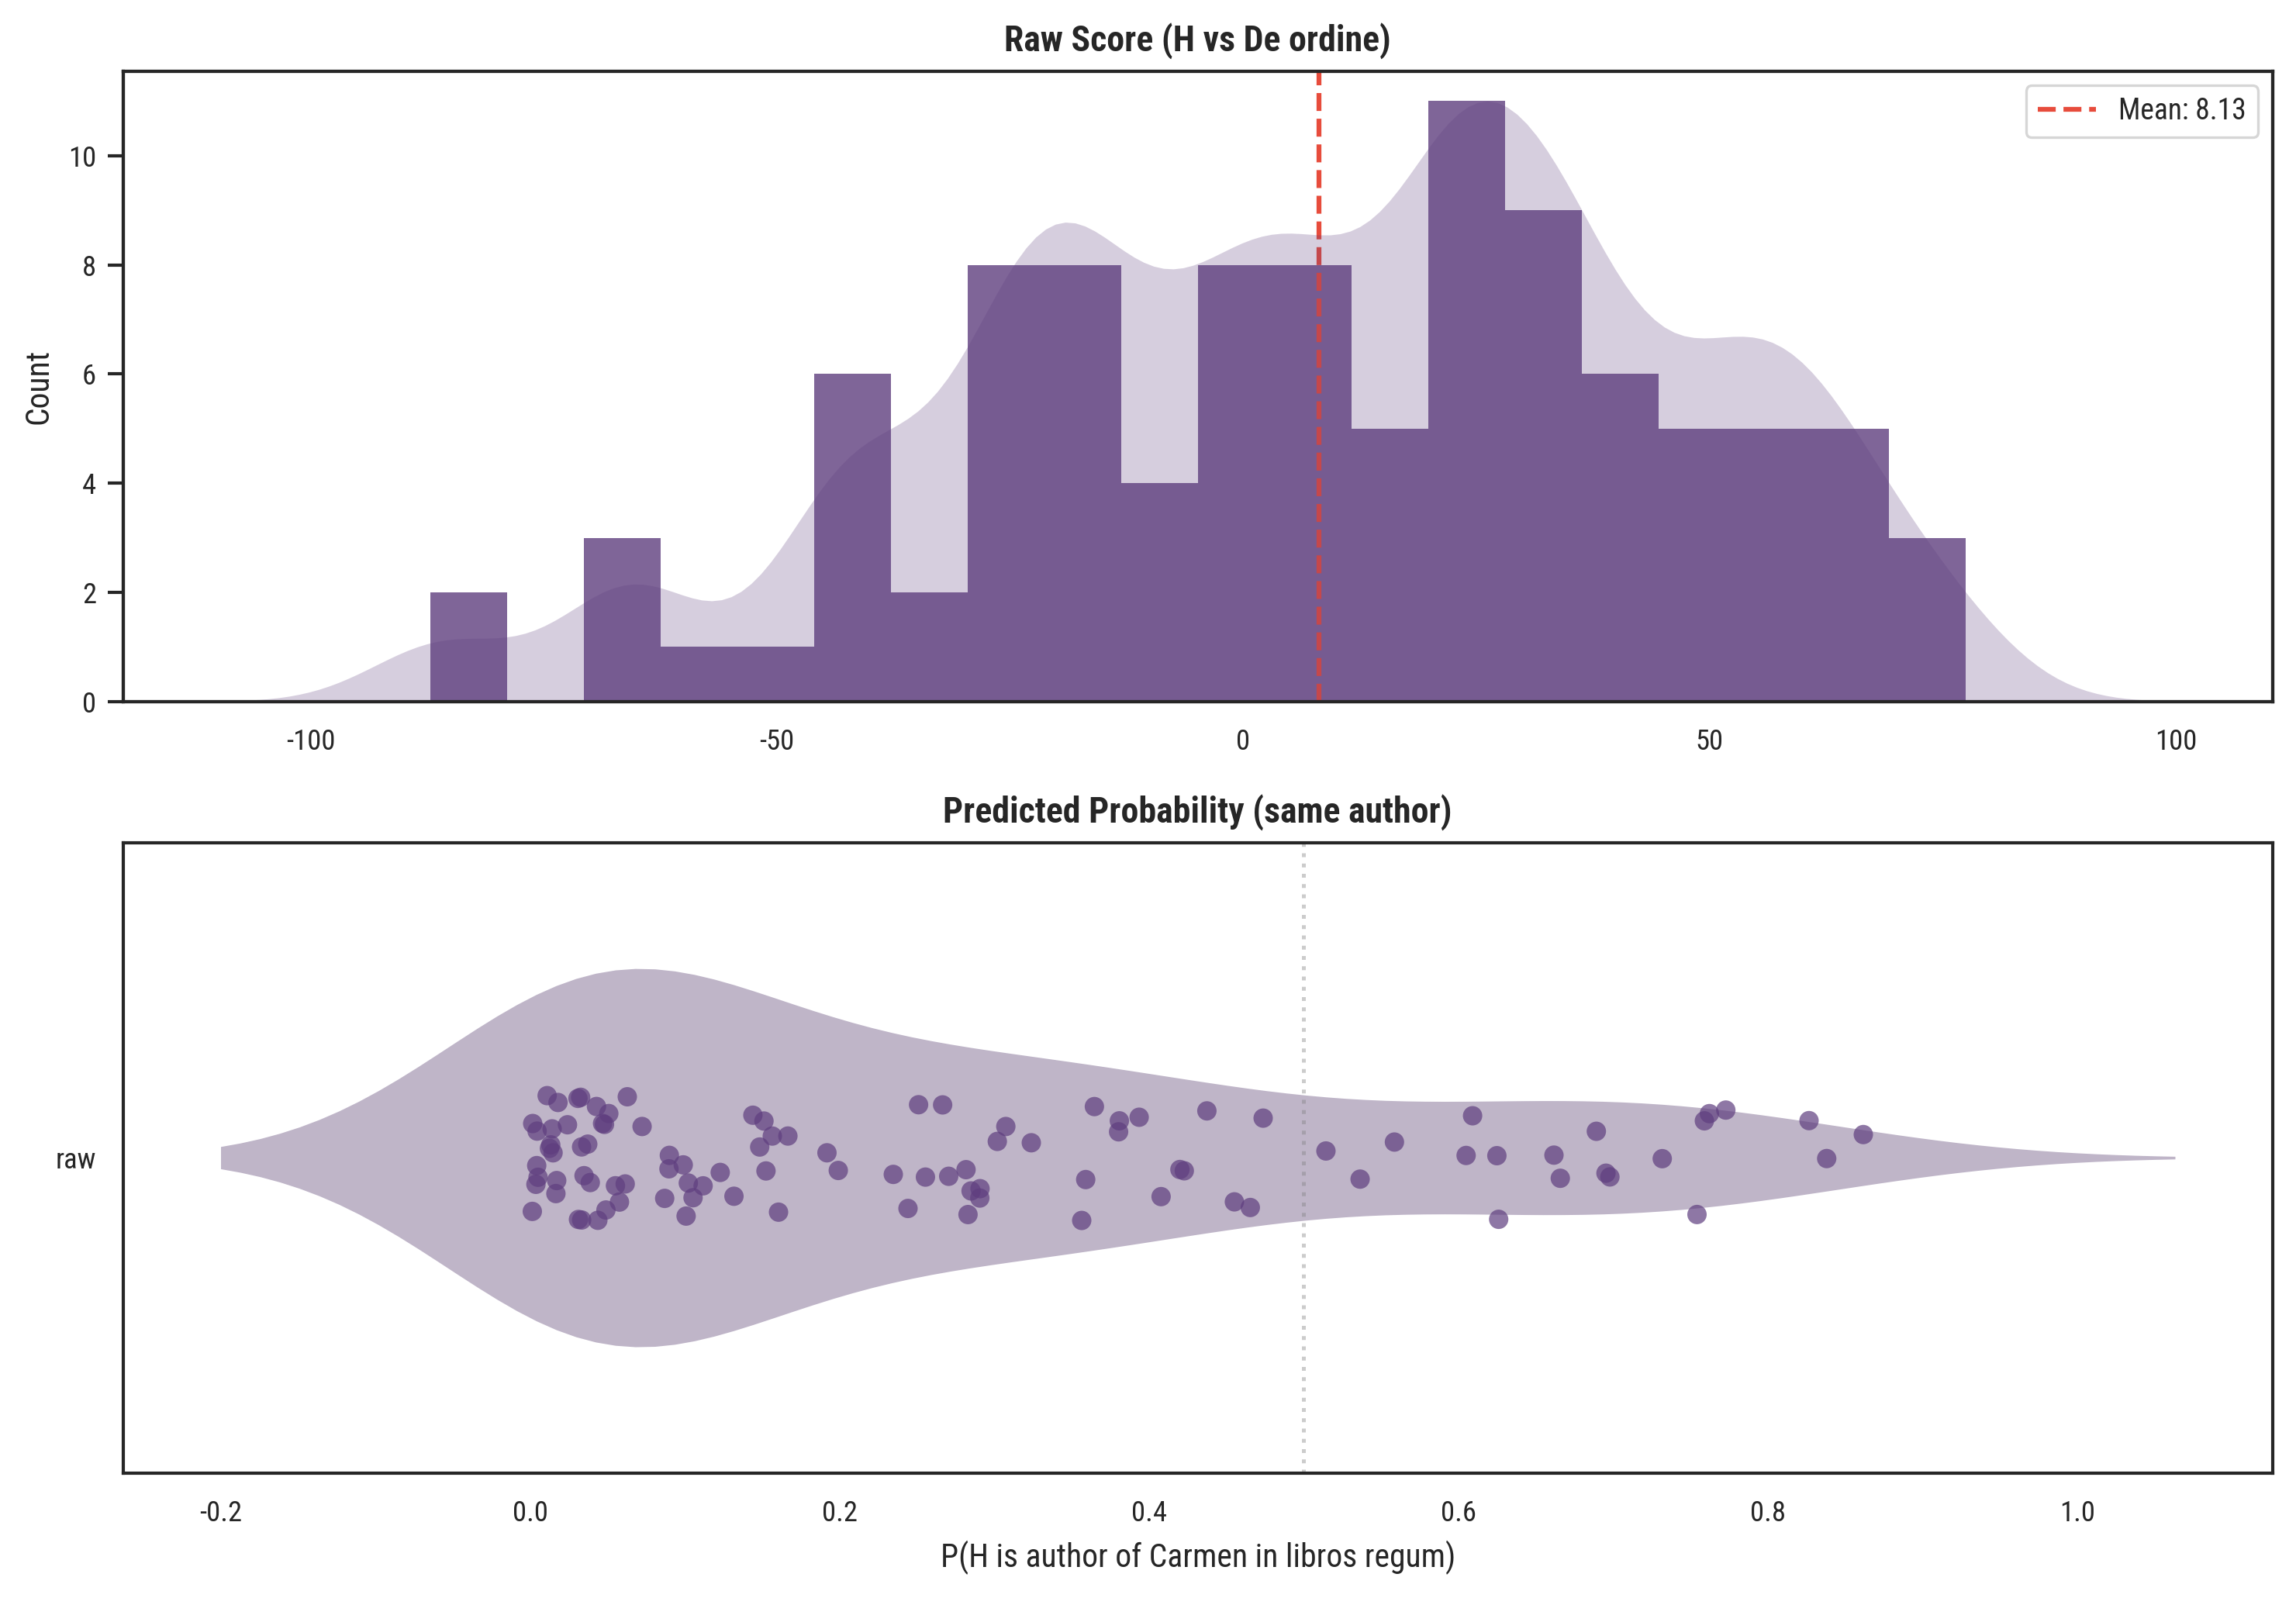

In [59]:
# Visualization: histplot of raw scores + stripplot/violin of probabilities
fig, axes = plt.subplots(2, 1, figsize=(10, 7), dpi=300)

for ax in axes:
    ax.grid(False)

color = "#5f3e7f"

# Row 1: Raw score distribution with KDE overlay
ax = axes[0]
sns.histplot(data=df, x="score", bins=20, ax=ax, color=color, alpha=0.8, linewidth=0)
ax2 = ax.twinx()
sns.kdeplot(
    data=df,
    x="score",
    ax=ax2,
    color=color,
    fill=True,
    linewidth=0,
    alpha=0.25,
    bw_adjust=0.5,
)
ax2.set_yticklabels([])
ax2.set_yticks([])
ax2.set_ylabel("")
ax.set_title("Raw Score (H vs De ordine)", fontweight="bold", fontsize=11)
ax.set_xlabel("")
ax.set_ylabel("Count")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
mean_val = df["score"].mean()
ax.axvline(
    mean_val,
    color="#e74c3c",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_val:.2f}",
)
ax.legend(loc="upper right", fontsize=9)

# Row 2: Probability stripplot + violin
ax = axes[1]
ax.grid(False)
df_plot = pd.DataFrame(
    {
        "probability": df["probability"].tolist(),
        "model": ["raw"] * len(df),
    }
)
sns.violinplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    width=0.6,
    inner=None,
    density_norm="width",
    alpha=0.4,
    linewidth=0,
    legend=False,
)
sns.stripplot(
    data=df_plot,
    x="probability",
    y="model",
    hue="model",
    ax=ax,
    palette=[color],
    size=6,
    jitter=True,
    alpha=0.7,
    legend=False,
)
ax.set_title("Predicted Probability (same author)", fontweight="bold", fontsize=11)
ax.set_xlabel("P(H is author of Carmen in libros regum)")
ax.set_ylabel("")
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()

## Evaluate Against All Authors

Now run the same 100 evaluations against every other author in the test corpus. For authors with fewer than 2000 tokens, we use their total token count as `known_size`.

In [61]:
# Compute known_size for each author
author_sizes = {}
for author in sorted(test_corpus.get_unique_values("author")):
    author_corpus = test_corpus.filter_by_level("author", author)
    tokens = sum(len(s.text.split()) for s in author_corpus)
    known_size = min(2000, tokens)
    author_sizes[author] = known_size
    print(f"  {author:6s}: {tokens:6d} tokens → known_size={known_size}")

  AI    :   9861 tokens → known_size=2000
  AeC   :  14745 tokens → known_size=2000
  AeP   :   5806 tokens → known_size=2000
  B     :   1991 tokens → known_size=1991
  BC    :   6994 tokens → known_size=2000
  DC    :   6449 tokens → known_size=2000
  E     :   3326 tokens → known_size=2000
  FB    :  10684 tokens → known_size=2000
  GAp   :   6004 tokens → known_size=2000
  GAr   :  11367 tokens → known_size=2000
  GC    :  12123 tokens → known_size=2000
  GM    :   3379 tokens → known_size=2000
  GP    :  14417 tokens → known_size=2000
  GVS   :   4958 tokens → known_size=2000
  GiP   :   5741 tokens → known_size=2000
  H     :   1960 tokens → known_size=1960
  HA    :   5049 tokens → known_size=2000
  HP    :   7640 tokens → known_size=2000
  IH    :   9513 tokens → known_size=2000
  II    :   8181 tokens → known_size=2000
  M     :   5515 tokens → known_size=2000
  NLC   :   5253 tokens → known_size=2000
  OM    :   8012 tokens → known_size=2000
  OSE   :   3955 tokens → known_si

In [62]:
# Define the per-author evaluation function
@ray.remote
def run_evaluation_for_author(
    seed: int,
    known_author: str,
    known_size: int,
    target_tokens: int = 750,
) -> dict:
    """Run a single AV evaluation: De ordine vs a given known author."""
    rng = np.random.default_rng(seed)
    av = LambdaGAV()

    q_corpus = sample_corpus_to_token_count(ordine_corpus, target_tokens, rng)

    result = av.run_single_av_problem(
        known_entity=known_author,
        q_corpus=q_corpus,
        kr_corpus=test_corpus,
        known_tokens=known_size,
        reference_tokens=20000,
        order=8,
        num_references=10,
        rng=rng,
    )

    return {
        "author": known_author,
        "score": result["score"],
        "known_size": known_size,
    }

In [63]:
N_EVALUATIONS = 100
# Run evaluations for all authors
ray.init()
print(f"Ray initialized with {ray.available_resources().get('CPU', 4)} CPUs")

master_rng = np.random.default_rng(123)

all_tasks = []
task_info = []  # (author, seed) for each task

for author, known_size in author_sizes.items():
    for i in range(N_EVALUATIONS):
        seed = master_rng.integers(0, 2**32 - 1)
        all_tasks.append(
            run_evaluation_for_author.remote(seed, author, known_size, TARGET_TOKENS)
        )
        task_info.append(author)

print(f"Created {len(all_tasks)} tasks for {len(author_sizes)} authors")

# Execute all tasks
all_results = []
for _ in tqdm(range(len(all_tasks)), desc="All evaluations"):
    ready, _ = ray.wait(all_tasks, num_returns=1)
    result = ray.get(ready[0])
    all_results.append(result)
    all_tasks.remove(ready[0])

print(f"✓ Completed {len(all_results)} evaluations")
ray.shutdown()

2026-09-04 11:21:13,235	INFO worker.py:2012 -- Started a local Ray instance.


Ray initialized with 8.0 CPUs


(pid=4302) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
(pid=4302)   from pandas.core.computation.check import NUMEXPR_INSTALLED
(pid=4302) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
(pid=4302)   from pandas.core import (


Created 3800 tasks for 38 authors


All evaluations: 100%|█████████████████████| 3800/3800 [20:39<00:00,  3.07it/s]
(pid=4300) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed). [repeated 7x across cluster]
(pid=4300)   from pandas.core.computation.check import NUMEXPR_INSTALLED [repeated 7x across cluster]
(pid=4300) /opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed). [repeated 7x across cluster]
(pid=4300)   from pandas.core import ( [repeated 7x across cluster]


✓ Completed 3800 evaluations


In [64]:
# Convert to DataFrame and compute probabilities
df_all = pd.DataFrame(all_results)
df_all["probability"] = model.predict_proba(df_all["score"].values.reshape(-1, 1))[:, 1]

# Summary: mean probability per author
summary = df_all.groupby("author")["probability"].agg(["mean", "std", "count"]).round(4)
summary = summary.sort_values("mean", ascending=False)
print("\n=== Mean Predicted Probability by Author ===")
print(summary)


=== Mean Predicted Probability by Author ===
          mean     std  count
author                       
U3      0.8005  0.2582    100
FB      0.6725  0.2810    100
U1      0.6623  0.2785    100
HA      0.6374  0.3109    100
U2      0.5399  0.2863    100
U11     0.4950  0.2985    100
B       0.4273  0.2897    100
U7      0.3691  0.2930    100
M       0.3012  0.2785    100
RT      0.2621  0.2347    100
DC      0.2620  0.2662    100
GiP     0.1841  0.2206    100
H       0.1836  0.2299    100
HP      0.1287  0.2071    100
GAp     0.1164  0.1712    100
NLC     0.1156  0.1713    100
RC      0.1126  0.1707    100
AeC     0.1019  0.1836    100
SG      0.0699  0.0997    100
GM      0.0554  0.0920    100
U5      0.0399  0.0829    100
GAr     0.0354  0.0756    100
GVS     0.0324  0.0833    100
U8      0.0171  0.0566    100
GC      0.0133  0.0302    100
U6      0.0088  0.0337    100
OSE     0.0082  0.0310    100
AI      0.0081  0.0292    100
OM      0.0071  0.0162    100
IH      0.0034  0.0095  

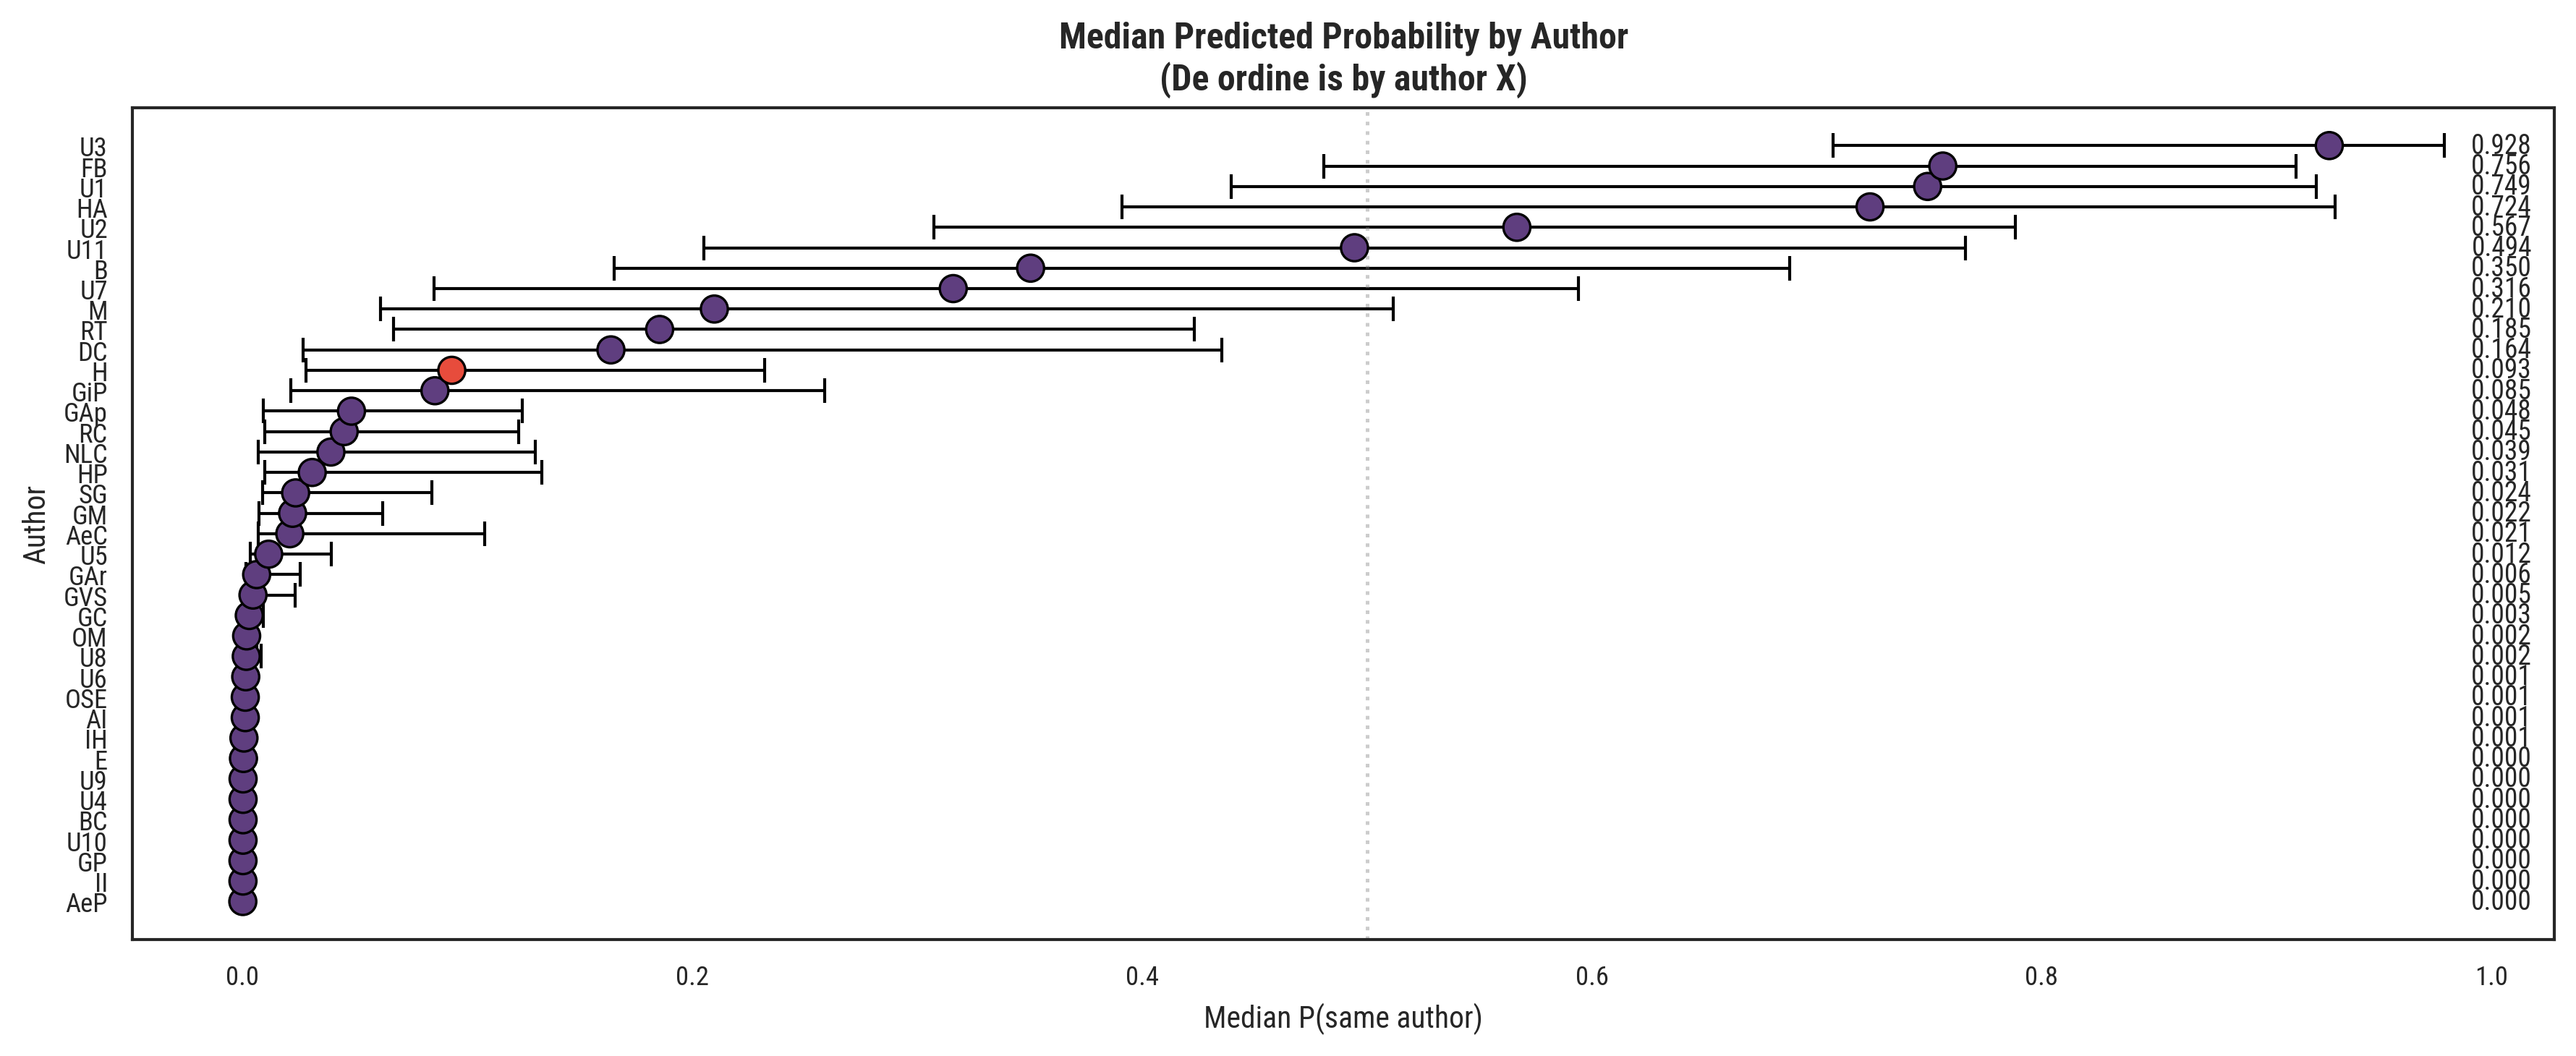

In [65]:
# Visualization: median probability per author with IQR whiskers
fig, ax = plt.subplots(figsize=(12, 5), dpi=300)
ax.grid(False)

# Compute stats per author
stats = df_all.groupby("author")["probability"].agg(
    ["median", lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]
)
stats.columns = ["median", "q25", "q75"]
stats = stats.sort_values("median", ascending=True)
authors_ordered = stats.index.tolist()

# Color: highlight H differently
colors = ["#e74c3c" if a == "H" else "#5f3e7f" for a in authors_ordered]

# IQR whiskers
for i, author in enumerate(authors_ordered):
    row = stats.loc[author]
    ax.plot(
        [row["q25"], row["q75"]],
        [i, i],
        color="black",
        linewidth=1,
        solid_capstyle="round",
    )
    for q in [row["q25"], row["q75"]]:
        ax.plot(q, i, "|", color="black", markersize=8, markeredgewidth=1)

# Median dots
ax.scatter(
    stats["median"].values,
    range(len(authors_ordered)),
    c=colors,
    s=80,
    zorder=5,
    edgecolors="black",
    linewidth=0.8,
)

ax.set_yticks(range(len(authors_ordered)))
ax.set_yticklabels(authors_ordered)
ax.set_title(
    "Median Predicted Probability by Author\n(De ordine is by author X)",
    fontweight="bold",
    fontsize=12,
)
ax.set_xlabel("Median P(same author)")
ax.set_ylabel("Author")
ax.axvline(x=0.5, color="gray", linestyle=":", alpha=0.4)

# Add value labels on the right side of the plot
xlim = ax.get_xlim()
for i, (val, author) in enumerate(zip(stats["median"].values, authors_ordered)):
    ax.text(xlim[1] - 0.01, i, f"{val:.3f}", va="center", ha="right", fontsize=9)

plt.tight_layout()
plt.show()